# LAB ASSIGNMENT-1
## Discuss and Analyze Different Data Visualization Tools

**Dataset:** California Housing (sklearn)

**Tools covered:** Matplotlib, Seaborn, Plotly, Altair

**Environment:** conda `AI_Env`

## 1. Introduction to Data Visualization

Data visualization is the graphical representation of information and data. Using visual elements such as charts, graphs, and maps, it helps us:

- Identify patterns, trends, and outliers in complex datasets
- Communicate insights clearly to technical and non-technical audiences
- Support decision-making with evidence from data
- Explore relationships between variables during analysis

In this lab we analyze the **California Housing** dataset using four Python visualization libraries and compare their strengths, weaknesses, and best-fit scenarios.

## 2. Load Dataset & Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import altair as alt

from sklearn.datasets import fetch_california_housing

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

# Rename columns for readability
df = df.rename(columns={
    "MedInc": "MedianIncome",
    "HouseAge": "HouseAge",
    "AveRooms": "AvgRooms",
    "AveBedrms": "AvgBedrooms",
    "Population": "Population",
    "AveOccup": "AvgOccupancy",
    "Latitude": "Latitude",
    "Longitude": "Longitude",
    "MedHouseVal": "MedianHouseValue"
})

# Feature bins for categorical-style analysis
df["IncomeBand"] = pd.cut(
    df["MedianIncome"],
    bins=[0, 2, 4, 6, 8, 16],
    labels=["Very Low", "Low", "Medium", "High", "Very High"]
)
df["AgeBand"] = pd.cut(
    df["HouseAge"],
    bins=[0, 15, 30, 40, 55],
    labels=["New", "Mid", "Old", "Very Old"]
)

print("Shape:", df.shape)
print("\nFeature descriptions:")
for name, desc in zip(housing.feature_names + ["MedHouseVal"], list(housing.DESCR.split("Attribute Information:")[-1].split("\n")[2:11]) if False else []):
    pass

print("""
Features:
  MedianIncome     - median income in block group (tens of thousands of USD)
  HouseAge         - median house age in block group
  AvgRooms         - average number of rooms
  AvgBedrooms      - average number of bedrooms
  Population       - block group population
  AvgOccupancy     - average household members
  Latitude/Longitude - geographic location
  MedianHouseValue - target: median house value ($100,000s)
""")
df.head()

Shape: (20640, 11)

Feature descriptions:

Features:
  MedianIncome     - median income in block group (tens of thousands of USD)
  HouseAge         - median house age in block group
  AvgRooms         - average number of rooms
  AvgBedrooms      - average number of bedrooms
  Population       - block group population
  AvgOccupancy     - average household members
  Latitude/Longitude - geographic location
  MedianHouseValue - target: median house value ($100,000s)



,MedianIncome,HouseAge,AvgRooms,AvgBedrooms,Population,AvgOccupancy,Latitude,Longitude,MedianHouseValue,IncomeBand,AgeBand
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,Very High,Very Old
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,Very High,Mid
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,High,Very Old
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,Medium,Very Old
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,Low,Very Old


In [3]:
df.describe().round(2)

,MedianIncome,HouseAge,AvgRooms,AvgBedrooms,Population,AvgOccupancy,Latitude,Longitude,MedianHouseValue
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


---
## 3. Tool 1 — Matplotlib (Python)

### Overview
Matplotlib is the foundational 2D plotting library for Python. It provides fine-grained control over every element of a figure (axes, ticks, labels, colors, layouts) and is the backend that many other libraries (including Seaborn and Pandas plotting) build upon.

### Key capabilities & features
- Line, bar, scatter, histogram, box, pie, contour, and image plots
- Full customization of styles, annotations, and multi-subplot layouts
- Export to PNG, PDF, SVG, and more
- Works in scripts, notebooks, and GUIs

### Practical use case
**Publication-ready charts for a research report** — e.g., showing how median house value relates to median income with precise axis formatting and annotations for a journal/lab report.

### Strengths
- Extremely flexible and widely supported
- Excellent for static, publication-quality figures
- Large community and documentation

### Weaknesses
- Verbose API for complex plots
- Default aesthetics are plain compared to Seaborn/Plotly
- Limited interactivity (compared to Plotly/Altair)

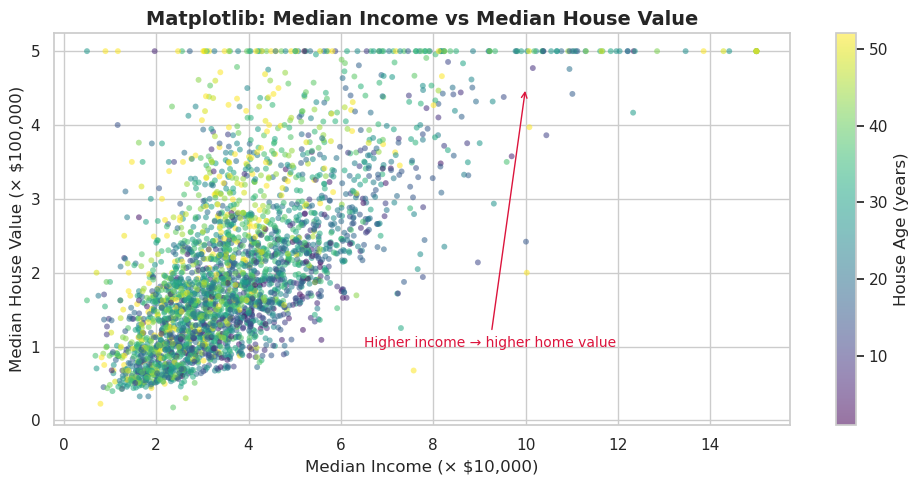

In [4]:
# Matplotlib Example 1: Scatter — Median Income vs Median House Value
fig, ax = plt.subplots(figsize=(10, 5))

sample = df.sample(3000, random_state=42)
sc = ax.scatter(
    sample["MedianIncome"],
    sample["MedianHouseValue"],
    c=sample["HouseAge"],
    cmap="viridis",
    alpha=0.55,
    s=18,
    edgecolors="none"
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("House Age (years)")

ax.set_title("Matplotlib: Median Income vs Median House Value", fontsize=14, fontweight="bold")
ax.set_xlabel("Median Income (× $10,000)")
ax.set_ylabel("Median House Value (× $100,000)")
ax.annotate(
    "Higher income → higher home value",
    xy=(10, 4.5),
    xytext=(6.5, 1.0),
    arrowprops=dict(arrowstyle="->", color="crimson"),
    fontsize=10,
    color="crimson"
)
plt.tight_layout()
plt.show()

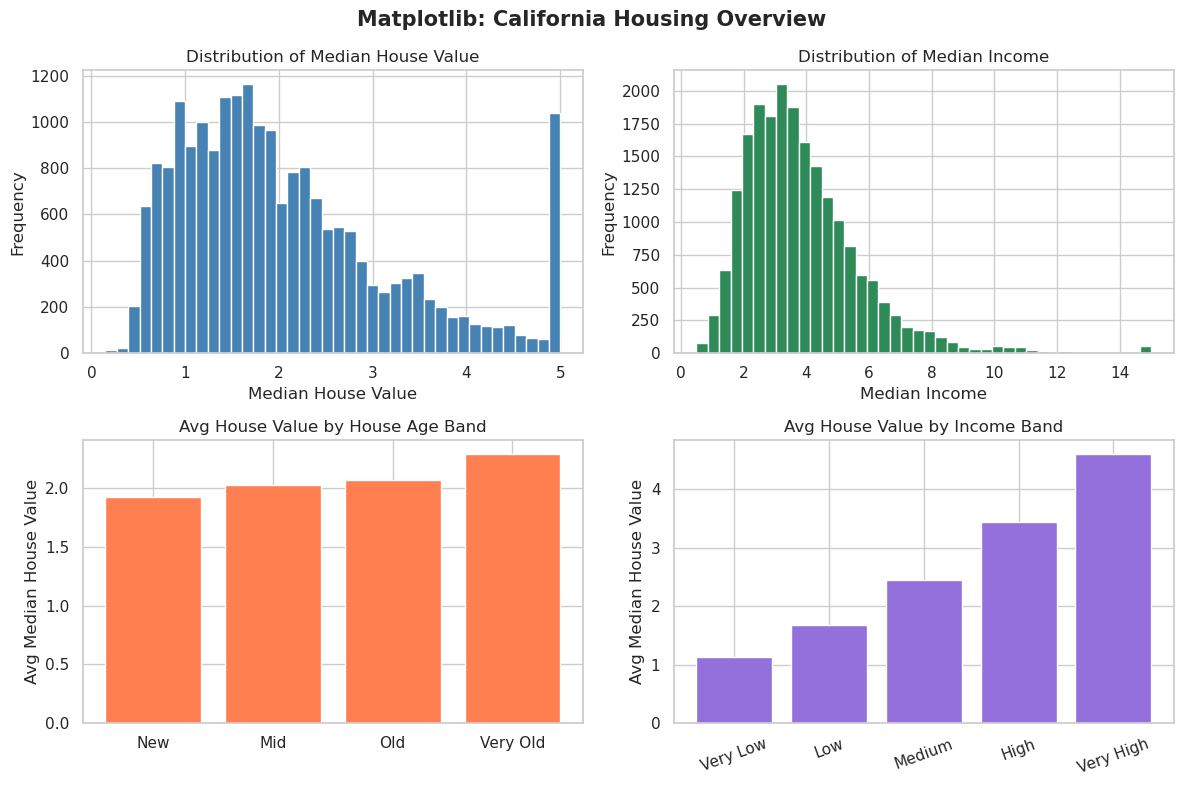

In [5]:
# Matplotlib Example 2: Multi-subplot dashboard (histograms + bar)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(df["MedianHouseValue"], bins=40, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Distribution of Median House Value")
axes[0, 0].set_xlabel("Median House Value")
axes[0, 0].set_ylabel("Frequency")

axes[0, 1].hist(df["MedianIncome"], bins=40, color="seagreen", edgecolor="white")
axes[0, 1].set_title("Distribution of Median Income")
axes[0, 1].set_xlabel("Median Income")
axes[0, 1].set_ylabel("Frequency")

age_means = df.groupby("AgeBand", observed=True)["MedianHouseValue"].mean()
axes[1, 0].bar(age_means.index.astype(str), age_means.values, color="coral")
axes[1, 0].set_title("Avg House Value by House Age Band")
axes[1, 0].set_ylabel("Avg Median House Value")

income_means = df.groupby("IncomeBand", observed=True)["MedianHouseValue"].mean()
axes[1, 1].bar(income_means.index.astype(str), income_means.values, color="mediumpurple")
axes[1, 1].set_title("Avg House Value by Income Band")
axes[1, 1].set_ylabel("Avg Median House Value")
axes[1, 1].tick_params(axis="x", rotation=20)

fig.suptitle("Matplotlib: California Housing Overview", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 4. Tool 2 — Seaborn (Python)

### Overview
Seaborn is a statistical visualization library built on top of Matplotlib. It simplifies creating informative plots with attractive default themes and integrates tightly with Pandas DataFrames.

### Key capabilities & features
- High-level APIs for distribution, relational, and categorical plots
- Built-in themes and color palettes
- Heatmaps, pair plots, violin/box/strip plots, regression plots
- Faceting via `FacetGrid` / `catplot` / `relplot`

### Practical use case
**Exploratory Data Analysis (EDA)** — quickly check correlations between housing features and visualize how house value varies across income bands using a heatmap and violin plot.

### Strengths
- Beautiful defaults with minimal code
- Excellent for statistical EDA
- Seamless DataFrame integration

### Weaknesses
- Less control than raw Matplotlib for highly custom figures
- Still primarily static (not interactive dashboards)
- Complex custom layouts may require falling back to Matplotlib

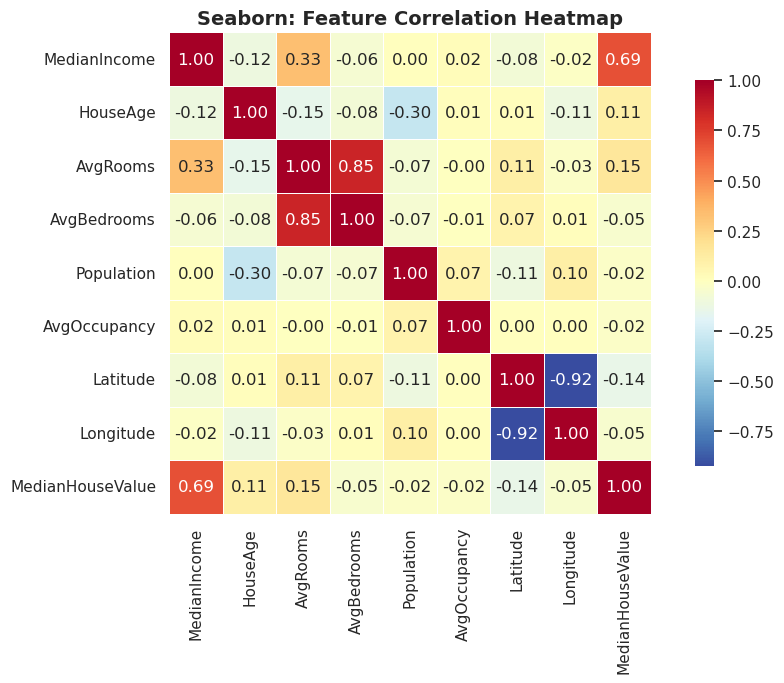

In [6]:
# Seaborn Example 1: Correlation heatmap
numeric_cols = [
    "MedianIncome", "HouseAge", "AvgRooms", "AvgBedrooms",
    "Population", "AvgOccupancy", "Latitude", "Longitude", "MedianHouseValue"
]
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Seaborn: Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

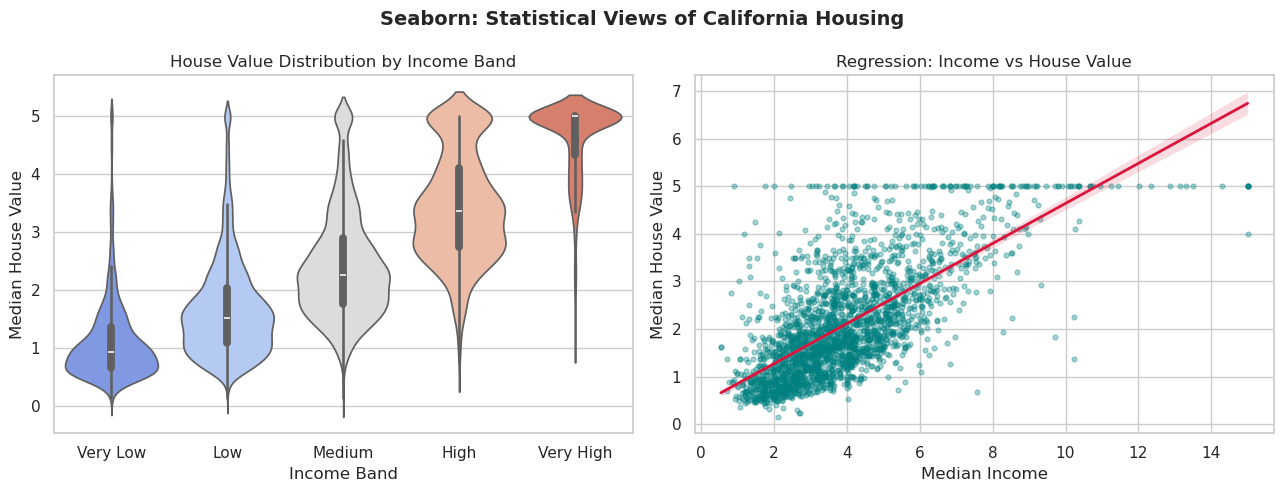

In [7]:
# Seaborn Example 2: Violin + regression plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.violinplot(
    data=df, x="IncomeBand", y="MedianHouseValue",
    hue="IncomeBand", palette="coolwarm", legend=False, ax=axes[0]
)
axes[0].set_title("House Value Distribution by Income Band")
axes[0].set_xlabel("Income Band")
axes[0].set_ylabel("Median House Value")

sns.regplot(
    data=df.sample(2500, random_state=7),
    x="MedianIncome",
    y="MedianHouseValue",
    scatter_kws={"alpha": 0.35, "s": 12, "color": "teal"},
    line_kws={"color": "crimson", "lw": 2},
    ax=axes[1]
)
axes[1].set_title("Regression: Income vs House Value")
axes[1].set_xlabel("Median Income")
axes[1].set_ylabel("Median House Value")

fig.suptitle("Seaborn: Statistical Views of California Housing", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

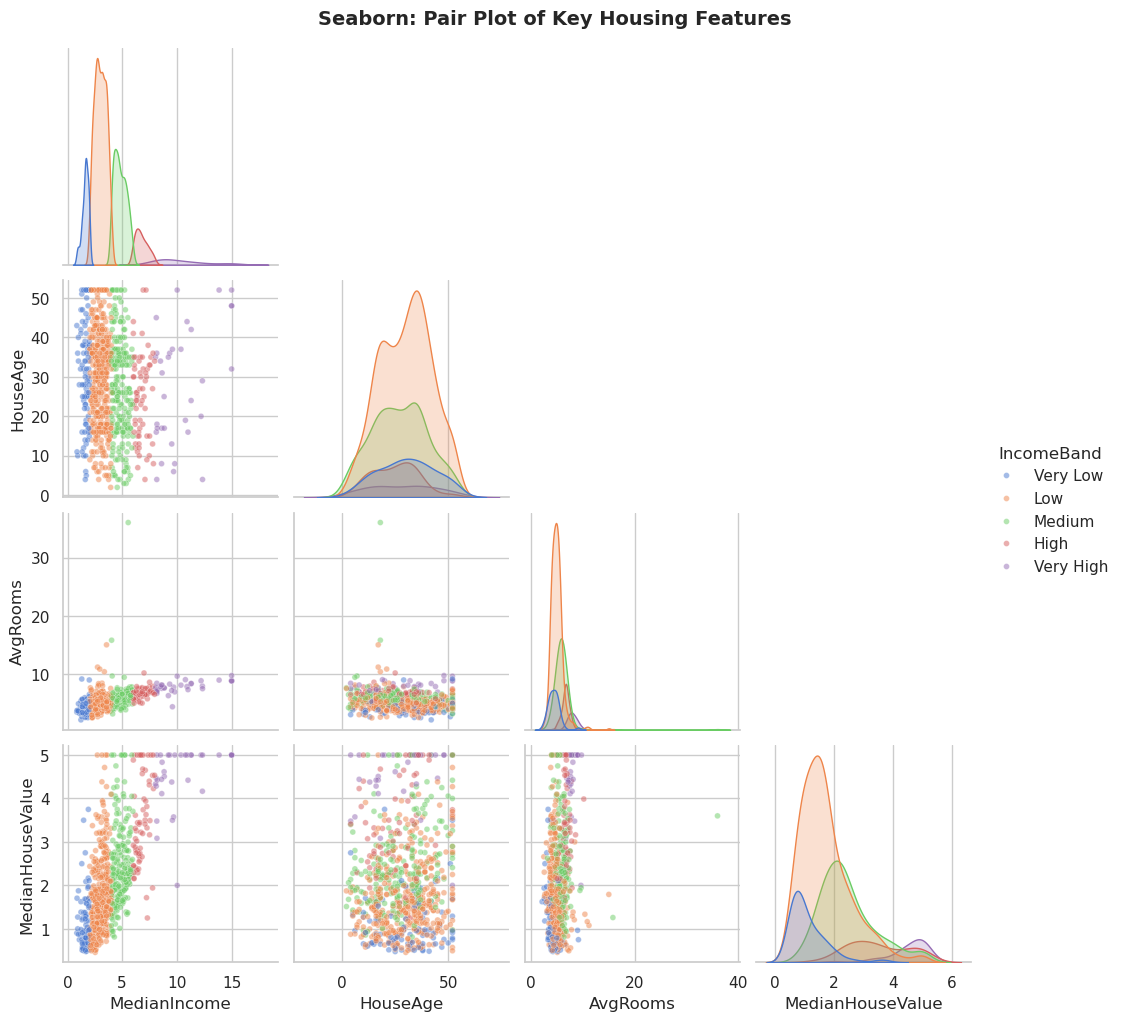

In [8]:
# Seaborn Example 3: Pairplot of key features (sample for speed)
pair_df = df[["MedianIncome", "HouseAge", "AvgRooms", "MedianHouseValue", "IncomeBand"]].sample(800, random_state=42)

g = sns.pairplot(
    pair_df,
    hue="IncomeBand",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 18},
    diag_kind="kde"
)
g.fig.suptitle("Seaborn: Pair Plot of Key Housing Features", y=1.02, fontsize=14, fontweight="bold")
plt.show()

---
## 5. Tool 3 — Plotly (Python)

### Overview
Plotly is an interactive visualization library that produces web-ready charts. Users can zoom, pan, hover for details, and export figures — ideal for dashboards and exploratory analysis in the browser.

### Key capabilities & features
- Interactive scatter, bar, line, 3D, map, and animated charts
- Hover tooltips, zoom, selection, and linked brushing
- Plotly Express for concise high-level syntax
- Easy embedding in notebooks, Dash apps, and web pages

### Practical use case
**Interactive geographic exploration** — map California block groups by location colored by median house value, then hover to inspect income and population for each point.

### Strengths
- Rich interactivity out of the box
- Great for dashboards and presentations
- Strong 3D and map support

### Weaknesses
- Heavier dependency / larger HTML output than static plots
- Fine styling can be more complex than Matplotlib
- Offline use of some features may need extra setup

In [9]:
# Plotly Example 1: Interactive geographic scatter map
map_df = df.sample(4000, random_state=42)

fig = px.scatter(
    map_df,
    x="Longitude",
    y="Latitude",
    color="MedianHouseValue",
    size="Population",
    size_max=18,
    hover_data={
        "MedianIncome": ":.2f",
        "HouseAge": True,
        "AvgRooms": ":.2f",
        "Population": True,
        "MedianHouseValue": ":.2f",
        "Longitude": False,
        "Latitude": False
    },
    color_continuous_scale="Turbo",
    title="Plotly: California Housing Map (color = house value, size = population)"
)
fig.update_layout(height=560, template="plotly_white")
fig.show()

In [10]:
# Plotly Example 2: Interactive 3D scatter
fig3d = px.scatter_3d(
    df.sample(2000, random_state=1),
    x="MedianIncome",
    y="HouseAge",
    z="MedianHouseValue",
    color="AvgRooms",
    opacity=0.65,
    color_continuous_scale="Viridis",
    title="Plotly 3D: Income × House Age × House Value"
)
fig3d.update_traces(marker=dict(size=3))
fig3d.update_layout(height=600, template="plotly_white")
fig3d.show()

In [11]:
# Plotly Example 3: Box plots by income band
fig_box = px.box(
    df,
    x="IncomeBand",
    y="MedianHouseValue",
    color="IncomeBand",
    points=False,
    title="Plotly: Median House Value by Income Band"
)
fig_box.update_layout(showlegend=False, template="plotly_white", height=450)
fig_box.show()

---
## 6. Tool 4 — Altair (Python)

### Overview
Altair is a declarative statistical visualization library based on Vega-Lite. You describe *what* you want (encodings: x, y, color, size) rather than *how* to draw it. Charts are interactive and grammar-of-graphics oriented.

### Key capabilities & features
- Declarative encoding of data fields to visual channels
- Built-in interactions: selection, zoom, linked charts
- Concise syntax for faceted and layered plots
- Vega-Lite JSON export for web embedding

### Practical use case
**Interactive linked exploration** — brush a region on an income–value scatter plot and see the matching geographic locations update automatically (ideal for teaching / exploratory demos).

### Strengths
- Clean, readable declarative API
- Excellent linked interactions and faceting
- Consistent grammar-of-graphics model

### Weaknesses
- Default row limit (~5,000) for large datasets (can be raised)
- Less low-level drawing control than Matplotlib
- Steeper learning curve if unfamiliar with Vega-Lite concepts

In [12]:
# Allow larger datasets for Altair in notebooks
alt.data_transformers.enable("default", max_rows=20000)

altair_df = df.sample(3000, random_state=42).copy()
altair_df["IncomeBand"] = altair_df["IncomeBand"].astype(str)
altair_df["AgeBand"] = altair_df["AgeBand"].astype(str)

# Altair Example 1: Interactive scatter with tooltip
chart1 = alt.Chart(altair_df).mark_circle(opacity=0.55).encode(
    x=alt.X("MedianIncome:Q", title="Median Income"),
    y=alt.Y("MedianHouseValue:Q", title="Median House Value"),
    color=alt.Color("HouseAge:Q", scale=alt.Scale(scheme="viridis"), title="House Age"),
    size=alt.Size("Population:Q", title="Population", scale=alt.Scale(range=[20, 300])),
    tooltip=[
        "MedianIncome", "MedianHouseValue", "HouseAge",
        "Population", "AvgRooms", "Latitude", "Longitude"
    ]
).properties(
    width=550,
    height=380,
    title="Altair: Income vs House Value (size = population)"
).interactive()

chart1

alt.Chart(...)

In [13]:
# Altair Example 2: Linked brush — scatter selects points shown on map
brush = alt.selection_interval()

base = alt.Chart(altair_df).add_params(brush)

scatter = base.mark_circle(opacity=0.5).encode(
    x=alt.X("MedianIncome:Q", title="Median Income"),
    y=alt.Y("MedianHouseValue:Q", title="Median House Value"),
    color=alt.condition(brush, alt.Color("IncomeBand:N", legend=alt.Legend(title="Income Band")), alt.value("lightgray")),
    tooltip=["MedianIncome", "MedianHouseValue", "IncomeBand"]
).properties(width=360, height=320, title="Brush a region here")

geo = base.mark_circle(opacity=0.55).encode(
    x=alt.X("Longitude:Q", scale=alt.Scale(domain=[-124.5, -114])),
    y=alt.Y("Latitude:Q", scale=alt.Scale(domain=[32.5, 42])),
    color=alt.condition(brush, alt.Color("MedianHouseValue:Q", scale=alt.Scale(scheme="turbo")), alt.value("lightgray")),
    tooltip=["Longitude", "Latitude", "MedianHouseValue", "MedianIncome"]
).properties(width=360, height=320, title="Selected locations appear here")

(scatter | geo).properties(title="Altair: Linked Brushing — Scatter ↔ Geography")

alt.HConcatChart(...)

In [14]:
# Altair Example 3: Faceted bar chart — avg house value by age & income band
agg = (
    altair_df.groupby(["AgeBand", "IncomeBand"], observed=True)["MedianHouseValue"]
    .mean()
    .reset_index()
)

chart3 = alt.Chart(agg).mark_bar().encode(
    x=alt.X("IncomeBand:N", title="Income Band", sort=["Very Low", "Low", "Medium", "High", "Very High"]),
    y=alt.Y("MedianHouseValue:Q", title="Avg Median House Value"),
    color=alt.Color("IncomeBand:N", legend=None),
    column=alt.Column("AgeBand:N", title="House Age Band", sort=["New", "Mid", "Old", "Very Old"]),
    tooltip=["AgeBand", "IncomeBand", "MedianHouseValue"]
).properties(
    width=120,
    height=220,
    title="Altair: Avg House Value by Income Band (faceted by Age)"
)

chart3

alt.Chart(...)

---
## 7. Comparative Analysis — Which Tool for Which Scenario?

| Scenario | Best tool(s) | Why |
|---|---|---|
| Research paper / lab report (static PNG/PDF) | **Matplotlib** | Precise layout control, publication exports |
| Fast statistical EDA (heatmaps, violin, pair plots) | **Seaborn** | High-level stats plots with nice defaults |
| Interactive dashboards, 3D, hover maps | **Plotly** | Zoom/pan/hover; easy web sharing |
| Linked brushing & declarative multi-view charts | **Altair** | Grammar-of-graphics + built-in selections |
| Teaching beginners Pandas-based analysis | Seaborn / Altair | Readable APIs close to the data |
| Custom low-level annotations & multi-axes | Matplotlib | Full artist-layer control |
| Stakeholder demo of California housing geography | Plotly | Interactive map-style scatter with tooltips |

### Summary of insights from California Housing
1. **Median income** is the strongest positive correlate of **median house value** (visible in Seaborn heatmap & regression).
2. Geographic clustering is clear on Plotly/Altair maps — coastal / urban areas show higher values.
3. House age alone is a weaker predictor; income band explains much more of value variation (violin & box plots).
4. Interactive tools (Plotly, Altair) help explore subgroups without rewriting plot code.

### Final recommendation
- Use **Matplotlib + Seaborn** as the default stack for coursework, EDA, and reports.
- Add **Plotly** when stakeholders need interactivity or geographic exploration.
- Use **Altair** when you want clean declarative charts with linked multi-view interactions.

---
## 8. Conclusion

This assignment explored four Python data visualization tools on the California Housing dataset:

| Tool | Type | Best for |
|---|---|---|
| Matplotlib | Imperative, static | Custom & publication figures |
| Seaborn | Statistical, static | EDA & correlation analysis |
| Plotly | Interactive | Dashboards, 3D, maps |
| Altair | Declarative, interactive | Linked views & grammar-of-graphics |

No single tool is best for every task. Choosing the right visualization library depends on whether you need statistical depth, pixel-perfect control, or rich interactivity.